# Embedding model decision

**Question:** which embedding model should localQuill use to index the style guides and the user's
documents?

**Decision: keep `nomic-embed-text`.** No candidate was clearly better on both Q&A and style-guide
retrieval, and switching would mean re-indexing every collection, including every user's uploads.

This notebook shows the evidence. Retrieval config and prompts are in `8_rag_evaluation.ipynb`
(test sets and metric definitions: §1–2 there). Numbers are read from `evaluation/reports/`; nothing
is re-run.

| § | Content |
|---|---|
| 1 | Candidates |
| 2 | Before: the DeepEval comparison couldn't separate the models |
| 3 | How we compared now |
| 4 | Q&A results |
| 5 | Style-guide results |
| 6 | Size and speed |
| 7 | Decision and when to revisit |

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from rag_eval_helpers import *
from run_rag_eval import prefixes_for

## 1. Candidates

All run locally through Ollama (checked November 2026). Size = `ollama list` on disk.

In [2]:
MODELS = ["nomic-embed-text", "embeddinggemma", "embeddinggemma-2:270m", "qwen3-embedding:0.6b", "mxbai-embed-large"]
SIZE_MB = {"nomic-embed-text": 274, "embeddinggemma": 621, "embeddinggemma-2:270m": 303,
           "qwen3-embedding:0.6b": 639, "mxbai-embed-large": 669}
NOTES = {
    "nomic-embed-text": "current model, baseline",
    "embeddinggemma": "Google, 300M, Gemma 3 based",
    "embeddinggemma-2:270m": "Gemma 4 based (Oct 2026); :740m is the same text model + vision/audio parts",
    "qwen3-embedding:0.6b": "strong on public benchmarks, long context",
    "mxbai-embed-large": "tested in spring, for comparison",
}
COLOR = dict(zip(MODELS, SERIES))
pd.DataFrame({"size (MB)": SIZE_MB, "notes": NOTES})

,size (MB),notes
nomic-embed-text,274,"current model, baseline"
embeddinggemma,621,"Google, 300M, Gemma 3 based"
embeddinggemma-2:270m,303,Gemma 4 based (Oct 2026); :740m is the same text model + vision/audio parts
qwen3-embedding:0.6b,639,"strong on public benchmarks, long context"
mxbai-embed-large,669,"tested in spring, for comparison"


**Dropped:** all-MiniLM-L6-v2 (old, 256-token context). **EmbeddingGemma 2 :740m** was run too and gives
exactly the same results as :270m, because Ollama's :740m is the same text model plus parts only used
for images and audio:

In [3]:
def qa_row(r, k=3):
    m = metrics(cases_of(r, "qa", {"userdocs"}, "question"), k)
    return {"Hit@3": m["hit"], "MRR": m["mrr"]}
pd.DataFrame({tag: qa_row(run(tag, 1000, o, p)) | {"setup": f"overlap {o}, prefixes {'on' if p else 'off'}"}
              for tag in ("embeddinggemma-2:270m", "embeddinggemma-2:740m") for o, p in [(0, True)]}).T

,Hit@3,MRR,setup
embeddinggemma-2:270m,0.884615,0.744872,"overlap 0, prefixes on"
embeddinggemma-2:740m,0.884615,0.744872,"overlap 0, prefixes on"


## 2. Before: the DeepEval comparison couldn't separate the models

In spring the models were compared with DeepEval contextual recall (LLM judge, 4 questions). Same
settings for every run (chunk 1000, overlap 200, top_k 3). Bar = mean, line = lowest to highest of
the repeated runs:

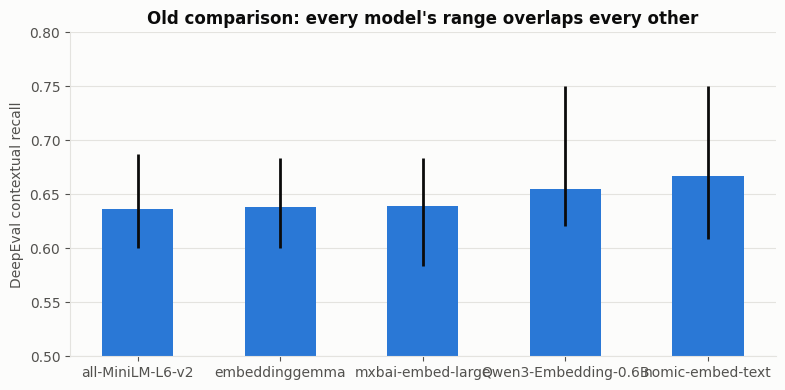

,mean,min,max,runs
model,,,,
all-MiniLM-L6-v2,0.64,0.60,0.69,4
embeddinggemma,0.64,0.60,0.68,4
mxbai-embed-large,0.64,0.58,0.68,4
Qwen3-Embedding-0.6B,0.66,0.62,0.75,4
nomic-embed-text,0.67,0.61,0.75,4


In [4]:
old = read_concatenated_json(REPORTS / "DISPRO1" / "eval_retrieval_results.jsonl")
old = pd.DataFrame([{
    "model": r["embedding_model"].split("/")[-1].split(":")[0].replace("-Q8_0", "").replace("all-minilm-l6-v2", "all-MiniLM-L6-v2"),
    "recall": r["average_recall"]}
    for r in old if r.get("average_recall") is not None and (r["chunk_size"], r["chunk_overlap"], r["top_k"]) == (1000, 200, 3)])
agg = old.groupby("model")["recall"].agg(["mean", "min", "max", "size"]).sort_values("mean")

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(agg.index, agg["mean"], width=0.5, color=BLUE)
ax.vlines(range(len(agg)), agg["min"], agg["max"], color=INK, linewidth=2)
ax.set_ylim(0.5, 0.8); ax.set_ylabel("DeepEval contextual recall")
ax.set_title("Old comparison: every model's range overlaps every other")
plt.tight_layout(); plt.show()
agg.round(2).rename(columns={"size": "runs"})

Every range overlaps every other range, so this data can't rank the models. Embeddings are
deterministic, so the spread is the judge, not the model. (Full explanation: notebook 8, §2.1.)

## 3. How we compared now

- **Test sets:** 26 Q&A questions on uploaded documents and 20 style drafts
  (notebook 8, §1). Metrics: Hit@k and MRR on labelled passages, no judge (notebook 8, §2.2).
- **Setup:** chunk 1000, overlap 0 and 200 (overlap 0 was best for Q&A, notebook 8 §3.3).
- **Prefixes on and off.** Some models are trained to expect an instruction in front of the text.
  Ollama doesn't add them, so the eval adds them itself:

In [5]:
pd.DataFrame({m: {"query prefix": repr(prefixes_for(m)[0]) if prefixes_for(m)[0] else "–",
                  "document prefix": repr(prefixes_for(m)[1]) if prefixes_for(m)[1] else "–"} for m in MODELS}).T

,query prefix,document prefix
nomic-embed-text,'search_query: ','search_document: '
embeddinggemma,'task: search result | query: ','title: none | text: '
embeddinggemma-2:270m,'task: search result | query: ','title: none | text: '
qwen3-embedding:0.6b,"'Instruct: Given a question or a text, retrieve relevant passages\nQuery: '",–
mxbai-embed-large,'Represent this sentence for searching relevant passages: ',–


## 4. Q&A results

### 4.1 Hit@3 (what the app sends), overlap 0

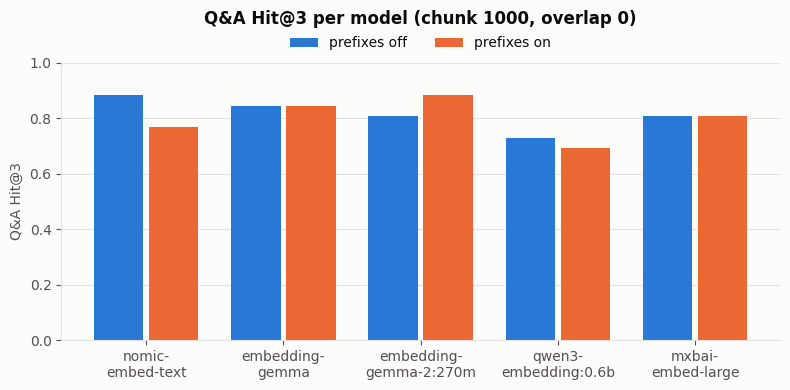

one question = 0.04


,prefixes off,prefixes on
nomic-embed-text,0.88,0.77
embeddinggemma,0.85,0.85
embeddinggemma-2:270m,0.81,0.88
qwen3-embedding:0.6b,0.73,0.69
mxbai-embed-large,0.81,0.81


In [6]:
k = APP_TOP_K["userdocs"]
qa = pd.DataFrame({
    "prefixes off": [score(run(m, 1000, 0, False), "qa", {"userdocs"}, "question", k) for m in MODELS],
    "prefixes on": [score(run(m, 1000, 0, True), "qa", {"userdocs"}, "question", k) for m in MODELS],
}, index=MODELS)
labels = ["nomic-\nembed-text", "embedding-\ngemma", "embedding-\ngemma-2:270m", "qwen3-\nembedding:0.6b", "mxbai-\nembed-large"]

fig, ax = plt.subplots(figsize=(8, 4))
grouped_bars(ax, qa.set_axis(labels), [BLUE, ORANGE], f"Q&A Hit@{k}")
ax.set_title(f"Q&A Hit@{k} per model (chunk 1000, overlap 0)", pad=28)
legend_on_top(ax)
plt.tight_layout(); plt.show()
print("one question = 0.04")
qa.round(2)

### 4.2 Hit@k for k = 1 … 8 (each model with its better prefix setting)

Do the models differ if the app sent more chunks?

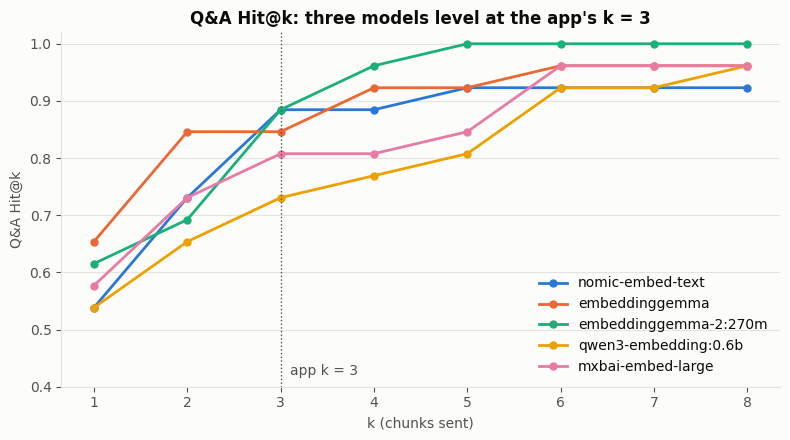

,k=1,k=2,k=3,k=4,k=5,k=6,k=7,k=8
nomic-embed-text (no prefix),0.54,0.73,0.88,0.88,0.92,0.92,0.92,0.92
embeddinggemma (no prefix),0.65,0.85,0.85,0.92,0.92,0.96,0.96,0.96
embeddinggemma-2:270m (prefix),0.62,0.69,0.88,0.96,1.00,1.00,1.00,1.00
qwen3-embedding:0.6b (no prefix),0.54,0.65,0.73,0.77,0.81,0.92,0.92,0.96
mxbai-embed-large (prefix),0.58,0.73,0.81,0.81,0.85,0.96,0.96,0.96


In [7]:
best = {m: max([False, True], key=lambda p: (score(run(m, 1000, 0, p), "qa", {"userdocs"}, "question", 3),
                                             score(run(m, 1000, 0, p), "qa", {"userdocs"}, "question", 3, "mrr"))) for m in MODELS}
ks = range(1, K_MAX + 1)
fig, ax = plt.subplots(figsize=(8, 4.5))
curves = {}
for m in MODELS:
    ys = [score(run(m, 1000, 0, best[m]), "qa", {"userdocs"}, "question", k_) for k_ in ks]
    curves[f"{m} ({'prefix' if best[m] else 'no prefix'})"] = ys
    ax.plot(ks, ys, color=COLOR[m], linewidth=2, marker="o", markersize=5, label=m)
ax.axvline(3, color=INK_2, linestyle=":", linewidth=1); ax.text(3.1, 0.42, "app k = 3", color=INK_2)
ax.set_xlabel("k (chunks sent)"); ax.set_ylabel("Q&A Hit@k"); ax.set_ylim(0.4, 1.02)
ax.set_title("Q&A Hit@k: three models level at the app's k = 3")
ax.legend(loc="lower right")
plt.tight_layout(); plt.show()
pd.DataFrame(curves, index=[f"k={k_}" for k_ in ks]).T.round(2)

### 4.3 MRR: is the answer ranked first?

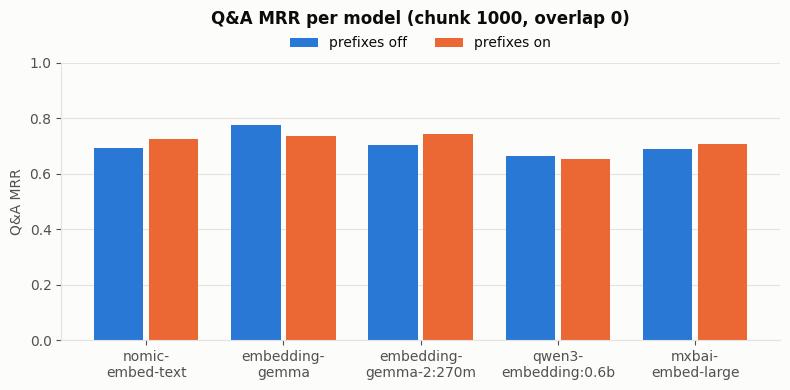

,prefixes off,prefixes on
nomic-embed-text,0.69,0.73
embeddinggemma,0.78,0.74
embeddinggemma-2:270m,0.70,0.74
qwen3-embedding:0.6b,0.66,0.65
mxbai-embed-large,0.69,0.71


In [8]:
mrr = pd.DataFrame({
    "prefixes off": [score(run(m, 1000, 0, False), "qa", {"userdocs"}, "question", K_MAX, "mrr") for m in MODELS],
    "prefixes on": [score(run(m, 1000, 0, True), "qa", {"userdocs"}, "question", K_MAX, "mrr") for m in MODELS],
}, index=MODELS)
fig, ax = plt.subplots(figsize=(8, 4))
grouped_bars(ax, mrr.set_axis(labels), [BLUE, ORANGE], "Q&A MRR")
ax.set_title("Q&A MRR per model (chunk 1000, overlap 0)", pad=28)
legend_on_top(ax)
plt.tight_layout(); plt.show()
mrr.round(2)

### 4.4 Overlap 0 beats 200 for every model

So the overlap decision (notebook 8, decision 2) doesn't depend on the model:

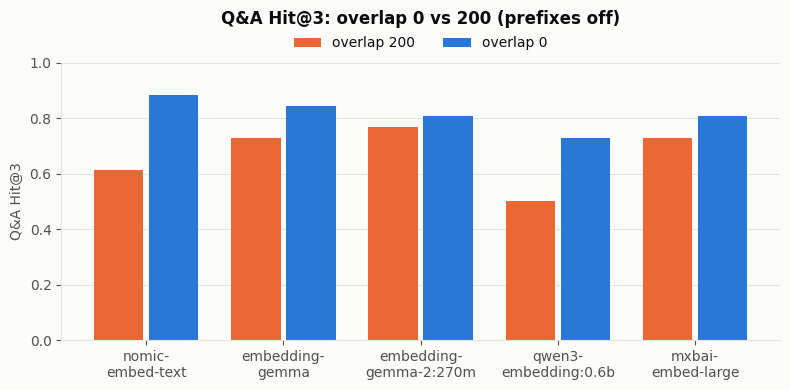

,overlap 200,overlap 0
nomic-embed-text,0.62,0.88
embeddinggemma,0.73,0.85
embeddinggemma-2:270m,0.77,0.81
qwen3-embedding:0.6b,0.50,0.73
mxbai-embed-large,0.73,0.81


In [9]:
ov = pd.DataFrame({
    "overlap 200": [score(run(m, 1000, 200, False), "qa", {"userdocs"}, "question", k) for m in MODELS],
    "overlap 0": [score(run(m, 1000, 0, False), "qa", {"userdocs"}, "question", k) for m in MODELS],
}, index=MODELS)
fig, ax = plt.subplots(figsize=(8, 4))
grouped_bars(ax, ov.set_axis(labels), [ORANGE, BLUE], f"Q&A Hit@{k}")
ax.set_title(f"Q&A Hit@{k}: overlap 0 vs 200 (prefixes off)", pad=28)
legend_on_top(ax)
plt.tight_layout(); plt.show()
ov.round(2)

## 5. Style-guide results

Grammar and feedback search the style guides. With the app's old query (keywords + draft) every
model fails the same way (it finds passages about the draft's topic, notebook 8 §3.1), so the models
are compared with the two queries that name the problem:
- `llm`: a short problem description written by a model first (usable in the app)
- `issue`: the hand-written label (upper bound)

Hit@5 over all 20 drafts, overlap 0, prefixes on:

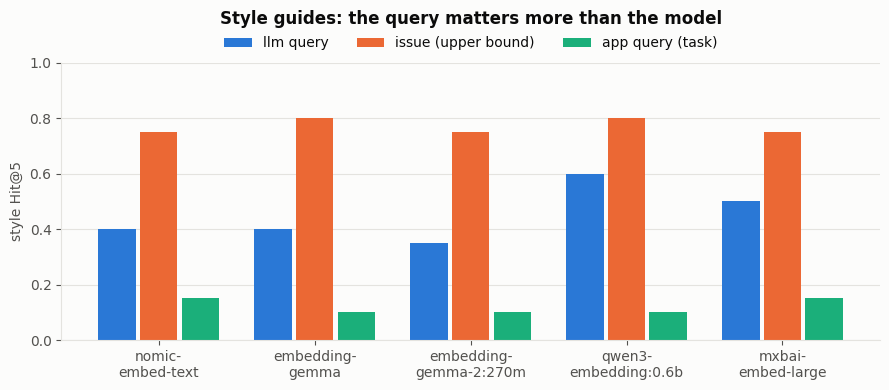

one draft = 0.05


,llm query,issue (upper bound),app query (task)
nomic-embed-text,0.40,0.75,0.15
embeddinggemma,0.40,0.80,0.10
embeddinggemma-2:270m,0.35,0.75,0.10
qwen3-embedding:0.6b,0.60,0.80,0.10
mxbai-embed-large,0.50,0.75,0.15


In [10]:
STYLE = GRAMMAR | FEEDBACK
st = pd.DataFrame({
    "llm query": [score(run(m, 1000, 0, True), "style", STYLE, "llm", 5) for m in MODELS],
    "issue (upper bound)": [score(run(m, 1000, 0, True), "style", STYLE, "issue", 5) for m in MODELS],
    "app query (task)": [score(run(m, 1000, 0, True), "style", STYLE, "task", 5) for m in MODELS],
}, index=MODELS)
fig, ax = plt.subplots(figsize=(9, 4))
grouped_bars(ax, st.set_axis(labels), [BLUE, ORANGE, AQUA], "style Hit@5")
ax.set_title("Style guides: the query matters more than the model", pad=28)
legend_on_top(ax, ncol=3)
plt.tight_layout(); plt.show()
print("one draft = 0.05")
st.round(2)

Qwen3-Embedding is best with the `llm` query (0.60), but it is the weakest on Q&A (§4). For the
other models the differences are 1–2 drafts.

## 6. Size and speed

Quality (Q&A Hit@3, better prefix setting) against size on disk. Query time and the time to index
all test collections (Q&A documents + both style guides) on an RTX 2060 Super:

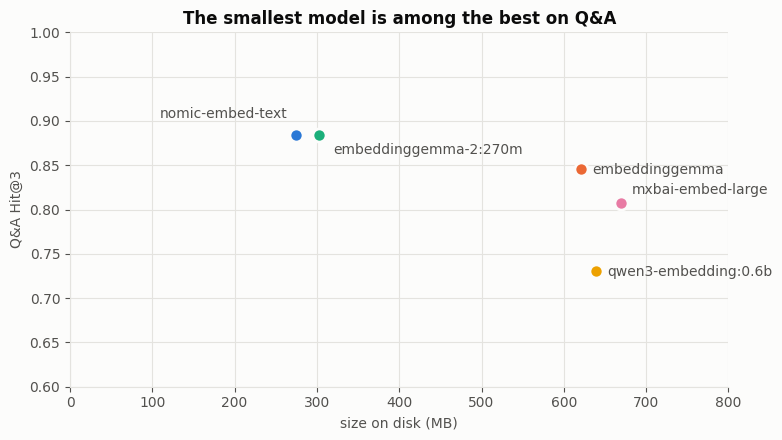

,size (MB),Q&A Hit@3,style Hit@5 (llm),query (ms),index all (s)
model,,,,,
nomic-embed-text,274,0.88,0.30,10.0,28.4
embeddinggemma,621,0.85,0.30,14.2,72.6
embeddinggemma-2:270m,303,0.88,0.35,12.9,48.6
qwen3-embedding:0.6b,639,0.73,0.50,13.8,68.2
mxbai-embed-large,669,0.81,0.50,13.9,50.7


In [11]:
rows = []
for m in MODELS:
    r = run(m, 1000, 0, best[m])
    rows.append({"model": m, "size (MB)": SIZE_MB[m], "Q&A Hit@3": score(r, "qa", {"userdocs"}, "question", 3),
                 "style Hit@5 (llm)": score(r, "style", STYLE, "llm", 5),
                 "query (ms)": r["query_ms_mean"], "index all (s)": r["index_seconds"]})
perf = pd.DataFrame(rows).set_index("model")

fig, ax = plt.subplots(figsize=(8, 4.5))
for m, row in perf.iterrows():
    ax.scatter(row["size (MB)"], row["Q&A Hit@3"], s=90, color=COLOR[m], edgecolor=SURFACE, linewidth=2, zorder=3)
    offset = {"nomic-embed-text": (-6, 12), "embeddinggemma-2:270m": (10, -14), "mxbai-embed-large": (8, 6)}.get(m, (8, -4))
    ax.annotate(m, (row["size (MB)"], row["Q&A Hit@3"]), xytext=offset, textcoords="offset points", color=INK_2,
                ha="right" if offset[0] < 0 else "left")
ax.set_xlabel("size on disk (MB)"); ax.set_ylabel("Q&A Hit@3"); ax.set_xlim(0, 800); ax.set_ylim(0.6, 1)
ax.grid(axis="x")
ax.set_title("The smallest model is among the best on Q&A")
plt.tight_layout(); plt.show()
perf.round(2)

## 7. Decision and when to revisit

**Keep `nomic-embed-text`, without prefixes.**

- **Q&A:** nomic (0.88), EmbeddingGemma (0.85) and EmbeddingGemma 2 (0.88 with prefixes) are within
  one question of each other at the app's k = 3. Qwen3-Embedding is the weakest (0.69–0.73).
- **MRR:** EmbeddingGemma puts the answer first a little more often (0.78 vs nomic 0.69), but
  finds it in the top 3 slightly less often. At k = 3 the answer only has to be in the prompt.
- **Style guides:** the query, not the model, decides (§5). Qwen3-Embedding is a few drafts ahead
  with the `llm` query, but loses on Q&A.
- **Cost of switching:** every collection must be re-indexed, including each user's uploads, and
  the new model is 1.1–2.4× larger. Not worth it for differences of one or two cases.
- **Prefixes** help EmbeddingGemma 2 and Qwen3-Embedding, but not nomic (Q&A Hit@3 0.88 → 0.77), so
  the app doesn't add them.

**Revisit if:**
- the app switches to an LLM-written search query for grammar and feedback (then Qwen3-Embedding's
  style advantage would count), or
- EmbeddingGemma 2 is adopted with prefixes: it is the only model to reach Q&A Hit@5 = 1.00
  (§4.2), at about the same size as nomic.